In [1]:
import matplotlib.pyplot as plot
import numpy as np
import pandas as pd
import re
import statsmodels.formula.api as sm

In [145]:
lottery_df = pd.read_csv( '../../data/lottery/merged/sfusd-lottery-all.csv' )
school_df = pd.read_csv( '../../data/lottery/merged/sfusd-school-id-mapping.csv' )
promotion_df = pd.read_csv( './Promotes from TK to K - Sheet1.csv' )

lottery_df = lottery_df \
    [( lottery_df.ay != '21-22' ) | ( lottery_df.choice_min != 6 ) | ( lottery_df.choice_max != 10 )] \
    .assign( num_requests = lottery_df.num_requests.fillna( 0 ).apply( lambda x: re.sub( r'(?:\,|\.\d*$)', '', str( x ) ) ) ) \
    .assign( num_requests = lambda _df: np.where( _df.num_requests.str.len() == 0, 0, _df.num_requests.fillna( 0 ) ).astype( int ) ) \
    .merge( lottery_df[lottery_df.grade == 'K'][['ay','school_id']].drop_duplicates() ) \
    [lambda _df: _df.grade == 'K']
unique_student_df = lottery_df[lottery_df.choice_max == 1][['ay','num_requests']].groupby( 'ay', as_index = False ).sum().rename( columns = { 'num_requests': 'ay_num_requests' } )
lottery_df = lottery_df \
    [lambda _df: _df.choice_min > 0] \
    [['ay','school_id','num_requests']] \
    .groupby( [ 'ay', 'school_id' ], as_index = False ) \
    .sum() \
    .merge( school_df, on = 'school_id' ) \
    .assign( log_num_requests = lambda _df: np.log2( _df.num_requests ) )
lottery_df = lottery_df[~lottery_df.school_id.isin( lottery_df[lottery_df.num_requests == 0].school_id.unique() )] \
    .merge( unique_student_df, on = 'ay' )

promotion_df = promotion_df \
    .rename( columns = {
        'idSchool': 'school_id',
        'Elilgible for Promotion': 'promotion_eligible',
        'Actually Promoted': 'promotion_accepted'
    } ) \
    [['school_id','promotion_eligible','promotion_accepted']]

lottery_df = lottery_df \
    .merge( promotion_df, on = 'school_id', how = 'left' ) \
    .assign(
        is_treatment = lambda _df: ( _df.ay == '25-26' ) & ( ~pd.isnull( _df.promotion_accepted ) ),
        num_requests_total = lambda _df: _df.num_requests + np.where( _df.ay == '25-26', _df.promotion_accepted.fillna( 0 ), 0 )
    ) \
    .assign( log_num_requests_total = lambda _df: np.log2( _df.num_requests_total ) )

/Users/kylew/git/sfusd-public/.venv/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [136]:
ols_linear = sm.ols( 'num_requests ~ C(ay) + C(school_name)', lottery_df )
ols_linear = ols_linear.fit()
# ols_linear.summary()

ols_log = sm.ols( 'log_num_requests ~ C(ay) + C(school_name)', lottery_df )
ols_log = ols_log.fit()
# ols_log.summary()

ols_log_total = sm.ols( 'log_num_requests_total ~ C(ay) + C(school_name)', lottery_df )
ols_log_total = ols_log_total.fit()
ols_log_total.summary()

ols_log_did = sm.ols( 'log_num_requests_total ~ C(ay) + C(school_name) + C(is_treatment)', lottery_df )
ols_log_did = ols_log_did.fit()
ols_log_did.summary()

y_var = 'log_num_requests_total'
model = ols_log_did
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     log_num_requests_total   R-squared:                       0.940
Model:                                OLS   Adj. R-squared:                  0.933
Method:                     Least Squares   F-statistic:                     129.1
Date:                    Mon, 29 Dec 2025   Prob (F-statistic):               0.00
Time:                            23:39:31   Log-Likelihood:                -385.14
No. Observations:                     893   AIC:                             966.3
Df Residuals:                         795   BIC:                             1436.
Df Model:                              97                                         
Covariance Type:                nonrobust                                         
======================================================================================================================================
                                                                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                              9.0994      0.122     74.380      0.000       8.859       9.340
C(ay)[T.13-14]                                                         0.1170      0.065      1.814      0.070      -0.010       0.244
C(ay)[T.14-15]                                                         0.4803      0.065      7.351      0.000       0.352       0.609
C(ay)[T.15-16]                                                         0.8466      0.064     13.141      0.000       0.720       0.973
C(ay)[T.16-17]                                                         0.9403      0.065     14.415      0.000       0.812       1.068
C(ay)[T.17-18]                                                         0.9909      0.065     15.166      0.000       0.863       1.119
C(ay)[T.19-20]                                                         0.4265      0.067      6.373      0.000       0.295       0.558
C(ay)[T.21-22]                                                         0.1822      0.065      2.789      0.005       0.054       0.310
C(ay)[T.22-23]                                                         0.2449      0.065      3.748      0.000       0.117       0.373
C(ay)[T.23-24]                                                        -0.0149      0.065     -0.228      0.820      -0.143       0.113
C(ay)[T.24-25]                                                        -0.1396      0.065     -2.136      0.033      -0.268      -0.011
C(ay)[T.25-26]                                                        -0.5041      0.087     -5.779      0.000      -0.675      -0.333
C(school_name)[T.Alvarado ES]                                          0.7500      0.161      4.648      0.000       0.433       1.067
C(school_name)[T.Alvarado Tk]                                         -2.5797      0.413     -6.244      0.000      -3.391      -1.769
C(school_name)[T.Argonne ES]                                           0.0922      0.161      0.572      0.568      -0.225       0.409
C(school_name)[T.Argonne Tk]                                          -2.3711      0.303     -7.826      0.000      -2.966      -1.776
C(school_name)[T.Bryant ES]                                           -2.0847      0.161    -12.919      0.000      -2.401      -1.768
C(school_name)[T.Buena Vista Horace Mann K-8]                         -0.8251      0.161     -5.120      0.000      -1.141      -0.509
C(school_name)[T.Carmichael (Bessie) K-8]                             -2.3316      0.161    -14.449      0.000      -2.648      -2.015
C(school_name)[T.Carver (Dr George W) ES]                            

In [137]:
lottery_df = lottery_df.assign( prediction = model.predict( lottery_df ) )

school_id                  786
school_name    Parks (Rosa) ES
Name: 55, dtype: object

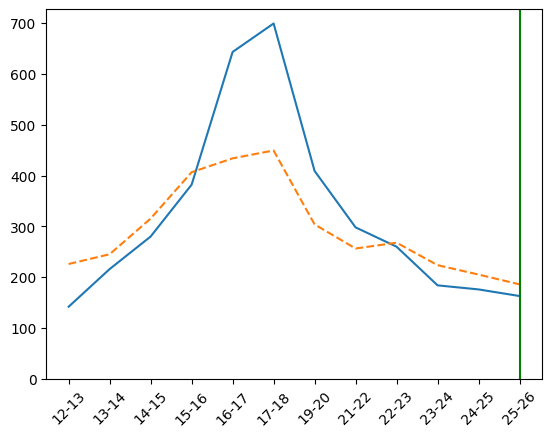

In [139]:
search = 'Parks'
plot_df = lottery_df \
    [lottery_df.school_name.str.contains( search ) & ~lottery_df.school_name.str.upper().str.contains( 'TK' )] \
    .sort_values( 'ay' )
display( plot_df[['school_id','school_name']].iloc[0] )

plot.plot( plot_df.ay, np.power( 2, plot_df[y_var] ) )
plot.xticks( rotation = 45 )
plot.plot( plot_df.ay, np.power( 2, plot_df.prediction ), linestyle = '--' )
plot.ylim( ( 0, None ) )

if True in plot_df.is_treatment.unique():
    plot.axvline( '25-26', color = 'green' )

else:
    plot.axvline( '25-26', color = 'red' )

plot.show()

In [115]:
lottery_df[['ay','num_requests']].groupby( 'ay' ).sum()

,num_requests
ay,
12-13,26964
13-14,30287
14-15,35680
15-16,46394
16-17,48547
17-18,49952
19-20,34794
21-22,28831
22-23,27914


In [159]:
#
# Restack everything
#
lottery_df = lottery_df \
    .assign( log_delta = lambda _df: np.log( _df.num_requests ) - np.log( _df.ay_num_requests ) )
ols_logit = sm.ols( 'log_delta ~ C(school_name) + C(ay) + 0', lottery_df )
ols_logit = ols_logit.fit()
# ols_logit.summary()

schools = [ 'Parks', 'Flynn', 'Sutro', 'Clarendon', 'Peabody', 'Argonne', 'Tenderloin' ]
params = ols_logit.params
for index in params.index:
    for s in schools:
        if s in index:
            print( f'{index}: {params[index]}' )
            break

params = model.params
for index in params.index:
    for s in schools:
        if s in index:
            print( f'{index}: {params[index]}' )

C(school_name)[Argonne ES]: -2.0922026704989127
C(school_name)[Argonne Tk]: -3.8084987993362165
C(school_name)[Clarendon ES]: -1.309888915629117
C(school_name)[Flynn (Leonard R) ES]: -2.7521393675018193
C(school_name)[Flynn Tk]: -4.36766734302546
C(school_name)[Parks (Rosa) ES]: -3.0457374729066173
C(school_name)[Peabody (George) ES]: -2.013602094599585
C(school_name)[Sutro ES]: -2.585481276199
C(school_name)[Tenderloin Community ES]: -4.119823989007389
C(school_name)[T.Argonne ES]: 0.09223287300993777
C(school_name)[T.Argonne Tk]: -2.371083226268161
C(school_name)[T.Clarendon ES]: 1.234757997249809
C(school_name)[T.Flynn (Leonard R) ES]: -0.8605383195421596
C(school_name)[T.Flynn Tk]: -3.177792911269678
C(school_name)[T.Parks (Rosa) ES]: -1.2789029427394447
C(school_name)[T.Peabody (George) ES]: 0.2195144837408911
C(school_name)[T.Sutro ES]: -0.6198548856269205
C(school_name)[T.Tenderloin Community ES]: -2.796544499206351


In [171]:
ols_logit.conf_int( 0.05 )

,0,1
C(school_name)[Alamo ES],-2.334842,-1.996674
C(school_name)[Alvarado ES],-1.803019,-1.464851
C(school_name)[Alvarado Tk],-4.506291,-3.399849
C(school_name)[Argonne ES],-2.261287,-1.923119
C(school_name)[Argonne Tk],-4.202421,-3.414576
...,...,...
C(ay)[T.21-22],0.181614,0.362362
C(ay)[T.22-23],0.255514,0.436262
C(ay)[T.23-24],0.099196,0.279944
C(ay)[T.24-25],0.044414,0.225162


In [173]:
lottery_df[lottery_df.ay == '25-26'].iloc[0]

601 / ( 601 + 3380 )

0.15096709369505149

In [208]:
P_t = 601
N_t = 3380
theta = pd.DataFrame( ols_logit.params ).reset_index()
theta.columns = [ 'param', 'theta' ]
theta = theta[theta.param.str.contains( 'school_name' )]
theta = theta.assign(
    school_name = lambda _df: _df.param.apply( lambda x: re.search( r'\[(.*?)\]$', x ).group( 1 ) )
).merge( promotion_df.merge( school_df ), how = 'left' )

theta_0t = ols_logit.params['C(ay)[T.25-26]']

# regression was ln \theta, so exp( \theta ) is exp-exp of param
f = lambda x: np.exp( np.exp( x ) )
theta = theta.assign( impact = ( ( 1 + f( theta_0t ) / f( theta.theta ) ) * theta.promotion_accepted.fillna( 0 ) - P_t ) / ( N_t + P_t ) )
theta[theta.promotion_eligible > 0][['school_name','impact']].describe()

,impact
count,42.000000
mean,-0.138120
std,0.003704
min,-0.146303
25%,-0.140971
50%,-0.137467
75%,-0.135305
max,-0.130815


In [229]:
theta = theta.assign( quality = np.exp( theta.theta ) )
conf_int = ols_logit.conf_int().reset_index()
conf_int.columns = [ 'param', 'ci_lower', 'ci_upper' ]
conf_int = conf_int[conf_int.param.str.contains( 'school_name' )]
conf_int = conf_int.assign(
    school_name = lambda _df: _df.param.apply( lambda x: re.search( r'\[(.*?)\]$', x ).group( 1 ) ) )

transform = lambda x: x
theta = theta.merge( conf_int[['school_name','ci_lower','ci_upper']] ).assign(
    quality = lambda _df: transform( _df.theta ),
    quality_lower = lambda _df: transform( _df.ci_lower ),
    quality_upper = lambda _df: transform( _df.ci_upper ),
    is_treatment = lambda _df: _df.promotion_eligible > 0
)

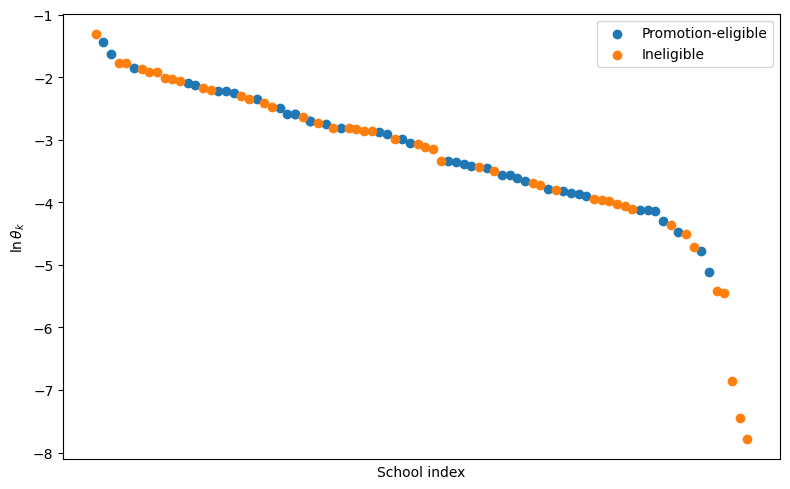

In [243]:
plot_df = theta[['school_id','school_name','is_treatment','quality','quality_lower','quality_upper']].sort_values( 'quality', ascending = False ).reset_index( drop = True )

figure, axes = plot.subplots( figsize = ( 8, 5 ) )

axes.scatter( plot_df.school_name.astype( str ), plot_df.quality, color = 'white' )

for treatment in [ True, False ]:
    mask = plot_df.is_treatment == treatment
    # axes.fill_between( plot_df[mask].school_name, plot_df[mask].quality_lower, plot_df[mask].quality_upper, alpha = 0.3, color = 'red' if not treatment else 'green' )
    axes.scatter( plot_df[mask].school_name, plot_df[mask].quality, label = 'Promotion-eligible' if treatment else 'Ineligible' )

plot.xticks( [], rotation = 65 )
plot.legend( loc = 'best' )

plot.xlabel( 'School index' )
plot.ylabel( r'$\ln \theta_k$' )

plot.tight_layout()
plot.show()